# [LELEC2870] - Machine Learning Project: Smurf Heart Failure
## Part 1: Tabular Data Baseline & Linear Regression

### Objectives & Constraints
1. Target: Predict the 10-year risk of heart failure $y \in [0, 1]$.
2. Feature Constraint: Doctor Smurf requests you select at most 6 of the original tabular features.
3. Model Family: Linear models (OLS, Weighted Least Squares, Ridge, Lasso).
4. Metric: Risk-Weighted Root Mean Squared Error (RW-RMSE):
   $$\text{RW-RMSE}(y, \hat{y}) = \sqrt{\frac{\sum_{i=1}^n w_i (y_i - \hat{y}_i)^2}{\sum_{i=1}^n w_i}}, \quad w_i = 1 + \frac{y_i}{0.1}$$

### Notebook Structure
- Step 1: Exploratory Data Analysis (EDA): Inspecting distributions, relationships, outliers, and feature types.
- Step 2: Preprocessing Pipeline: Categorical encoding (ordinal vs. nominal), feature scaling, and leakage prevention.
- Step 3: Feature Selection: Comparing Filters (Correlation, MI, mRMR), Wrappers (SFS), and Embedded methods.
- Step 4: Linear Modeling & Optimization: Standard OLS, Weighted Linear Regression (WLS), Regularized models, and prediction clipping.
- Step 5: Validation Strategy & Model Comparison: K-Fold cross-validation on `X_train` using RW-RMSE.
- Step 6: Test Generalization & Submission Export: Final evaluation on `X_test`, export to `y_pred.csv`, and report checklist.



Load the essential libraries and define the **RW-RMSE** criterion from the project guidelines.


In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.feature_selection import mutual_info_regression, SequentialFeatureSelector
from sklearn.metrics import make_scorer, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(style='whitegrid')
%matplotlib inline


### Metric: Risk-Weighted Root Mean Squared Error (RW-RMSE)
For Doctor Smurf, missing a high-risk patient is much more critical than over-diagnosing a low-risk patient.
A patient with $y=10\%$ risk has weight $w=2$, while a patient with $y=40\%$ has weight $w=5$.


In [55]:
def rw_rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    w = 1.0 + y_true / 0.1
    return np.sqrt(np.sum(w * (y_true - y_pred)**2) / np.sum(w))

def rmse(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    return np.sqrt(np.mean((y_true - y_pred)**2))

# Scorer for scikit-learn (greater_is_better=False because lower error is better)
rw_rmse_scorer = make_scorer(rw_rmse, greater_is_better=False)


## Step 1: Exploratory Data Analysis

Before writing any modeling code, we need to thoroughly explore the data.
Key questions to answer:
1. What data types are present in each column?
2. Are there missing values or anomalous readings?
3. What is the distribution of the target risk variable $y$?
4. How are categorical variables structured? Which ones are **ordinal** (natural ordering) vs **nominal** (pure labels)?
5. How features correlates with each other and with the target variable?


In [56]:
# Load labeled training and test sets
# y_train.csv and y_test.csv have no header
X_train_raw = pd.read_csv('data_student/data_labeled/X_train.csv')
y_train_raw = pd.read_csv('data_student/data_labeled/y_train.csv', header=None, names=['risk'])

X_test_raw = pd.read_csv('data_student/data_labeled/X_test.csv')
y_test_raw = pd.read_csv('data_student/data_labeled/y_test.csv', header=None, names=['risk'])

X_unlabeled = pd.read_csv('data_student/data_unlabeled/X.csv')

print(f"X_train shape: {X_train_raw.shape}, y_train shape: {y_train_raw.shape}")
print(f"X_test shape:  {X_test_raw.shape},  y_test shape:  {y_test_raw.shape}")
print(f"X_unlabeled shape: {X_unlabeled.shape}")


X_train shape: (1000, 14), y_train shape: (1000, 1)
X_test shape:  (500, 14),  y_test shape:  (500, 1)
X_unlabeled shape: (500, 14)


In [57]:
# Inspect sample rows and data types
X_train_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                1000 non-null   int64  
 1   blood_pressure     1000 non-null   float64
 2   calcium            1000 non-null   float64
 3   cholesterol        1000 non-null   float64
 4   hemoglobin         1000 non-null   float64
 5   height             1000 non-null   float64
 6   potassium          1000 non-null   float64
 7   profession         1000 non-null   object 
 8   sarsaparilla       1000 non-null   object 
 9   smurfberry_liquor  1000 non-null   object 
 10  smurfin_donuts     1000 non-null   object 
 11  vitamin_D          1000 non-null   float64
 12  weight             1000 non-null   float64
 13  img_filename       1000 non-null   object 
dtypes: float64(8), int64(1), object(5)
memory usage: 109.5+ KB


In [58]:
# Check for missing values
X_train_raw.isnull().sum()


age                  0
blood_pressure       0
calcium              0
cholesterol          0
hemoglobin           0
height               0
potassium            0
profession           0
sarsaparilla         0
smurfberry_liquor    0
smurfin_donuts       0
vitamin_D            0
weight               0
img_filename         0
dtype: int64

In [59]:
X_test_raw.isnull().sum()

age                  0
blood_pressure       0
calcium              0
cholesterol          0
hemoglobin           0
height               0
potassium            0
profession           0
sarsaparilla         0
smurfberry_liquor    0
smurfin_donuts       0
vitamin_D            0
weight               0
img_filename         0
dtype: int64

### 1.1 Target Variable Distribution ($y$)

Examine the distribution of heart failure risk in the training and test sets:
-Shape & Skewness: Right-skewed distribution with a long tail towards higher risk.
- Key Clinical Thresholds: Doctor Smurf begins worrying at $y = 10\%$
- Exceedance Curve (Survival Function): What proportion of Smurfs have risk $\ge X\%$?


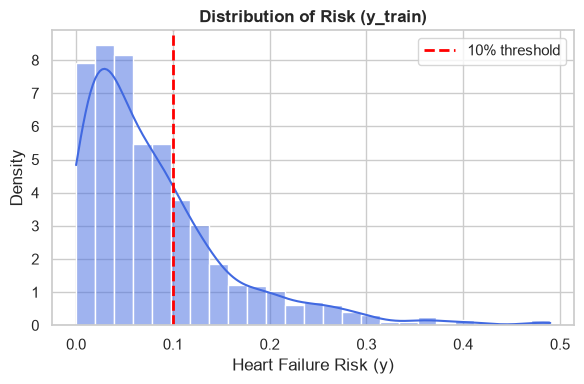

In [60]:
# Figure 1: Histogram + KDE
plt.figure(figsize=(6, 4))
sns.histplot(y_train_raw['risk'], kde=True, bins=25, color='royalblue', stat='density')
plt.axvline(0.10, color='red', linestyle='--', linewidth=2, label='10% threshold')
plt.title('Distribution of Risk (y_train)', fontsize=12, fontweight='bold')
plt.xlabel('Heart Failure Risk (y)')
plt.ylabel('Density')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


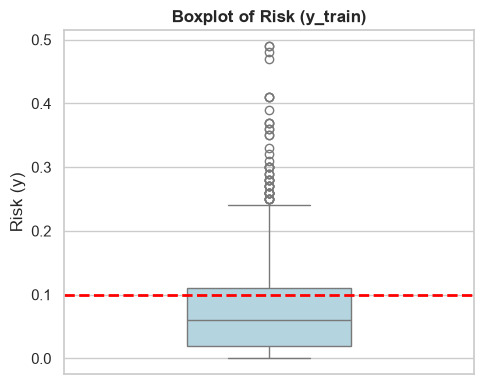

In [61]:
# Figure 2: Boxplot
plt.figure(figsize=(5, 4))
sns.boxplot(y=y_train_raw['risk'], color='lightblue', width=0.4)
plt.axhline(0.10, color='red', linestyle='--', linewidth=2)
plt.title('Boxplot of Risk (y_train)', fontsize=12, fontweight='bold')
plt.ylabel('Risk (y)')
plt.tight_layout()
plt.show()

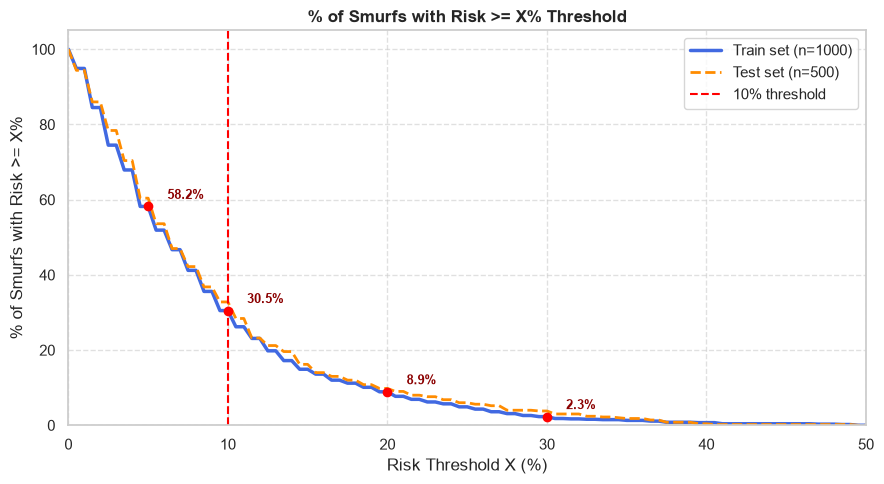

In [62]:
# Figure 3: Exceedance curve
thresholds = np.linspace(0, 0.50, 101)
pct_above_train = np.array([(y_train_raw['risk'] >= t).mean() * 100 for t in thresholds])
pct_above_test = np.array([(y_test_raw['risk'] >= t).mean() * 100 for t in thresholds])

plt.figure(figsize=(9, 5))
plt.plot(thresholds * 100, pct_above_train, color='royalblue', linewidth=2.5, label='Train set (n=1000)')
plt.plot(thresholds * 100, pct_above_test, color='darkorange', linewidth=2, linestyle='--', label='Test set (n=500)')
plt.axvline(10, color='red', linestyle='--', linewidth=1.5, label='10% threshold')

for t_val in [5, 10, 20, 30]:
    pct_val = (y_train_raw['risk'] >= (t_val / 100)).mean() * 100
    plt.plot(t_val, pct_val, marker='o', markersize=6, color='red')
    plt.annotate(f'{pct_val:.1f}%', xy=(t_val, pct_val), xytext=(t_val + 1.2, pct_val + 2),
                 fontsize=9, fontweight='bold', color='darkred')

plt.title('% of Smurfs with Risk >= X% Threshold', fontsize=12, fontweight='bold')
plt.xlabel('Risk Threshold X (%)')
plt.ylabel('% of Smurfs with Risk >= X%')
plt.xlim(0, 50)
plt.ylim(0, 105)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

Key insights obtained about distribution of ($y$): 
- No one above 50% risk 
- More than a half (58.2%) with grater than 5% risk, and 30.5% above Doctor's smurf threshold
- Median is 6%. The most dense interval, that is, the risk where a smursf is more probable to be in, is betwen 4% and 7%.

### 1.2 Categorical Variables Analysis
4 categorical features: `profession`, `sarsaparilla`, `smurfberry_liquor`, `smurfin_donuts`.

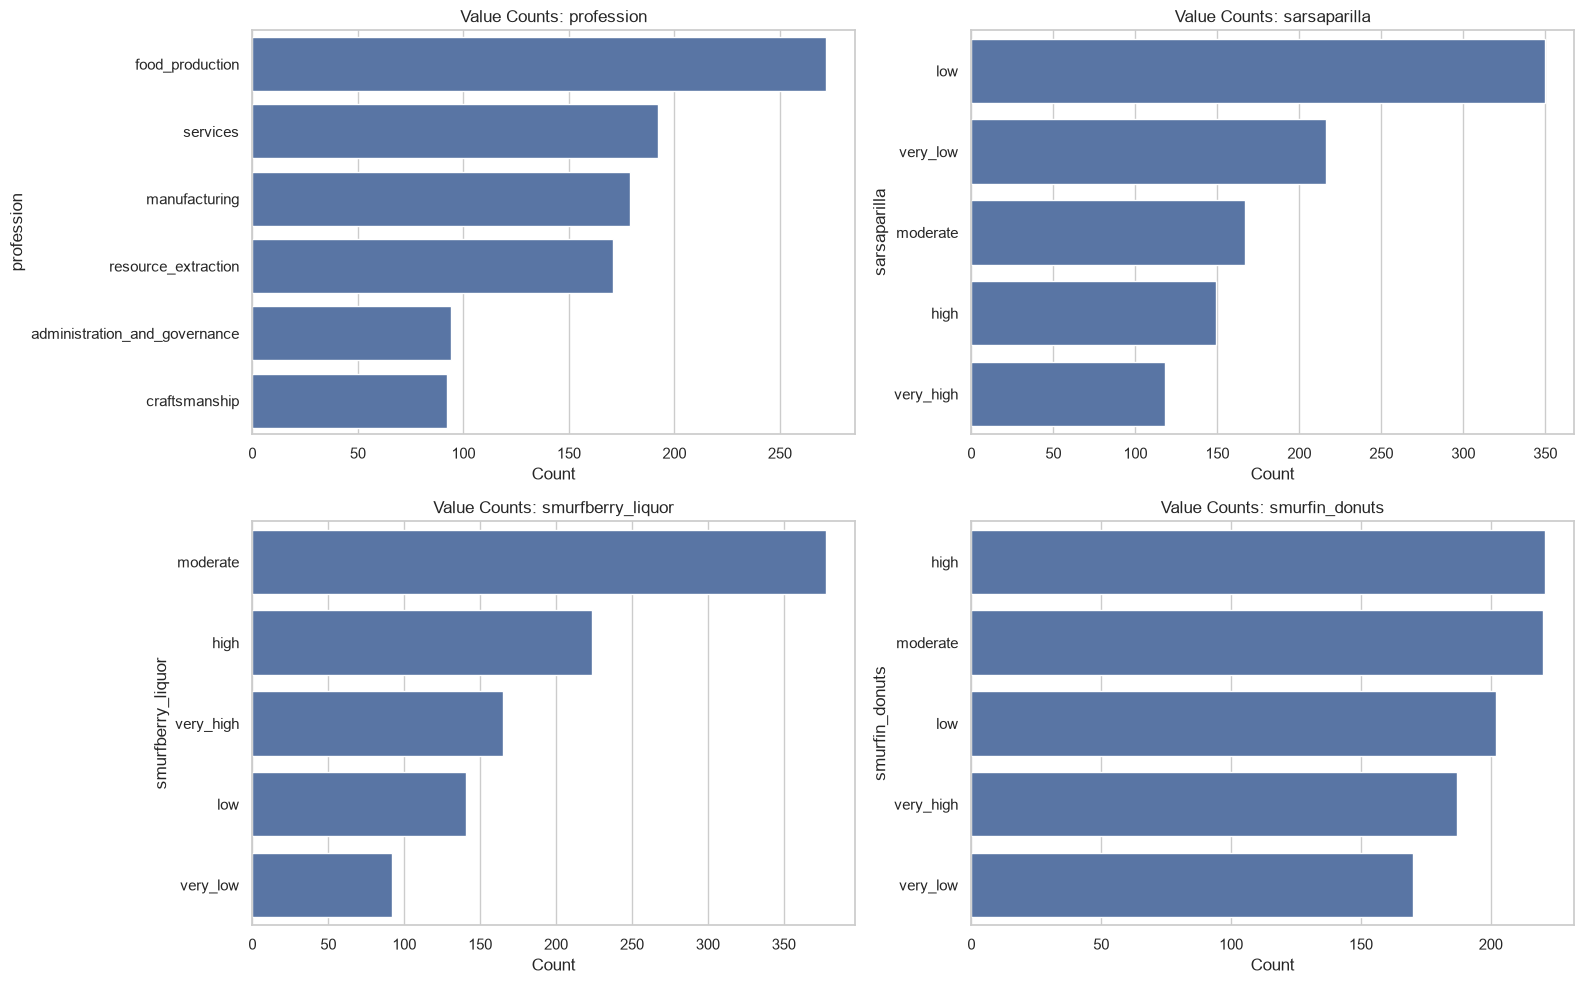

In [63]:
categorical_cols = ['profession', 'sarsaparilla', 'smurfberry_liquor', 'smurfin_donuts']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(data=X_train_raw, y=col, ax=axes[i], order=X_train_raw[col].value_counts().index)
    axes[i].set_title(f"Value Counts: {col}")
    axes[i].set_xlabel("Count")

plt.tight_layout()
plt.show()


- Nominal: `profession`
- Ordinal: `sarsaparilla`, `smurfberry_liquor`, `smufin_donuts`

### 1.3 Pairwise Feature Relationships & Multicollinearity
Correlation matrix among numerical features to check for redundancy.


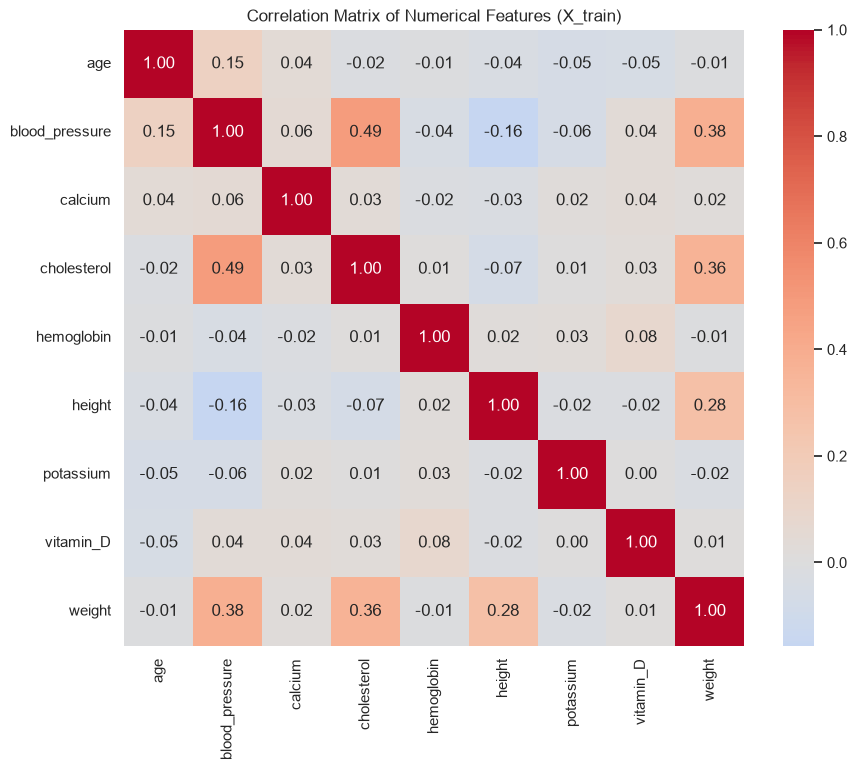

In [64]:
numerical_cols = X_train_raw.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(10, 8))
sns.heatmap(X_train_raw[numerical_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title("Correlation Matrix of Numerical Features (X_train)")
plt.show()


- Overall, it is observed a small correlation between variables
- For stranger as it seems, cholesterol correlates with blood_pressure (0.49) better than height correlates with weight (0.28). Smurf things

### 1.4 Feature Correlations with the Target Variable ($y$) & Answering Question 5

To thoroughly answer **Question 5 ("How features correlate with each other and with the target variable?")**, we examine:
1. **Feature-Target Correlation**: Which features are positive risk drivers, and which are protective?
2. **Linear Trends**: Scatter plots and regression trend lines for the strongest numerical predictors.
3. **Lifestyle Impact**: How risk shifts across ordered levels of sarsaparilla, liquor, and donuts.


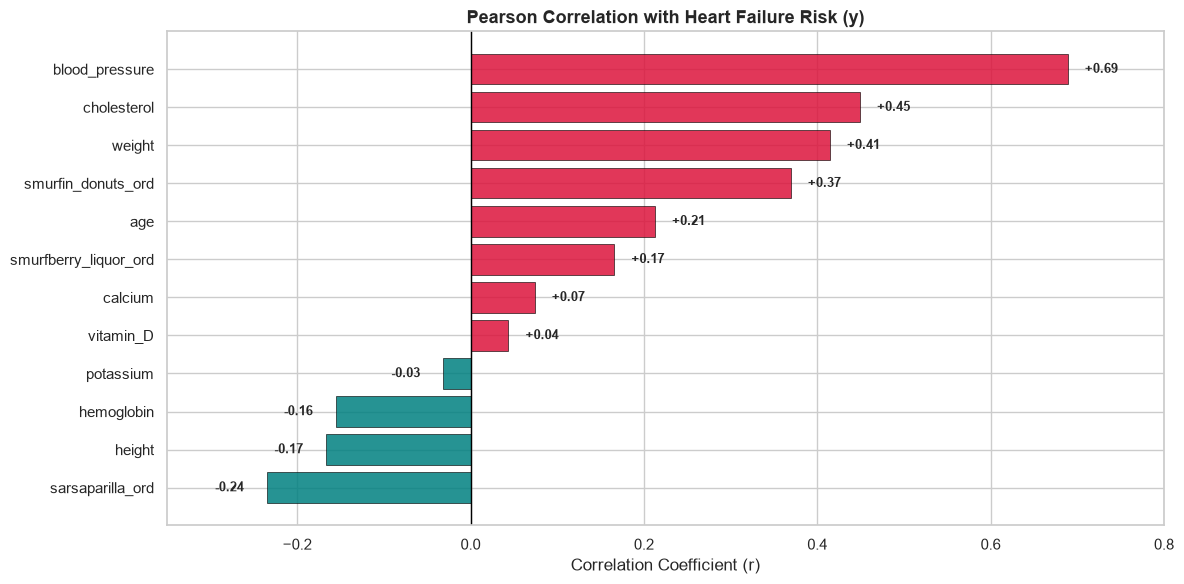

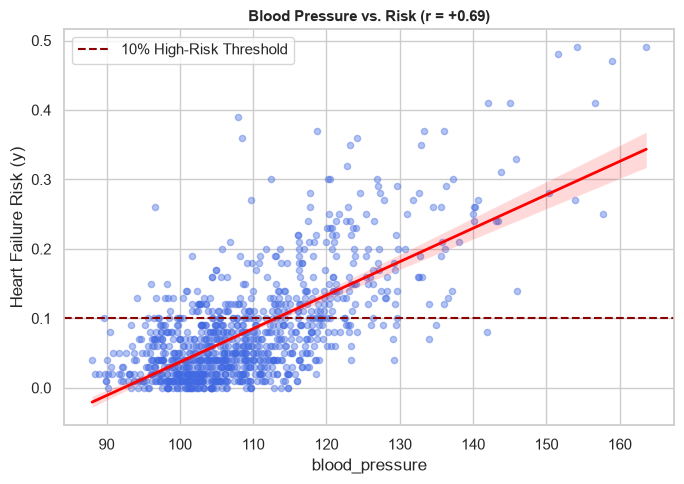

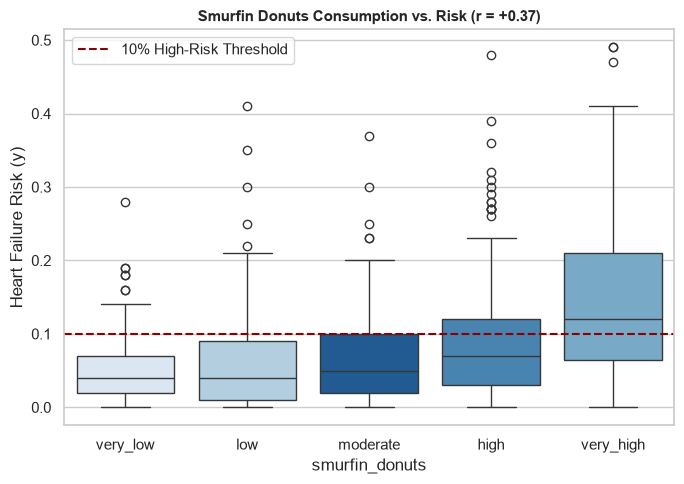

In [65]:
# Figure 1: feature-target correlations
plt.figure(figsize=(12, 6))
colors = ['teal' if val < 0 else 'crimson' for val in target_corrs.values]
bars = plt.barh(target_corrs.index, target_corrs.values, color=colors, alpha=0.85, edgecolor='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=1)
plt.title('Pearson Correlation with Heart Failure Risk (y)', fontsize=13, fontweight='bold')
plt.xlabel('Correlation Coefficient (r)')
plt.xlim(-0.35, 0.80)
for i, v in enumerate(target_corrs.values):
    offset = 0.02 if v >= 0 else -0.06
    plt.text(v + offset, i, f'{v:+.2f}', va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

# Figure 2: blood pressure vs risk
plt.figure(figsize=(7, 5))
sns.regplot(
    data=df_analysis,
    x='blood_pressure',
    y=y_train_raw['risk'],
    scatter_kws={'alpha': 0.4, 'color': 'royalblue', 's': 20},
    line_kws={'color': 'red', 'linewidth': 2}
)
plt.axhline(0.10, color='darkred', linestyle='--', label='10% High-Risk Threshold')
plt.title('Blood Pressure vs. Risk (r = +0.69)', fontsize=11, fontweight='bold')
plt.ylabel('Heart Failure Risk (y)')
plt.legend()
plt.tight_layout()
plt.show()

# Figure 3: donut consumption vs risk
plt.figure(figsize=(7, 5))
order_levels = ['very_low', 'low', 'moderate', 'high', 'very_high']
sns.boxplot(
    data=df_analysis,
    x='smurfin_donuts',
    y=y_train_raw['risk'],
    order=order_levels,
    hue='smurfin_donuts',
    palette='Blues',
    legend=False
)
plt.axhline(0.10, color='darkred', linestyle='--', label='10% High-Risk Threshold')
plt.title('Smurfin Donuts Consumption vs. Risk (r = +0.37)', fontsize=11, fontweight='bold')
plt.ylabel('Heart Failure Risk (y)')
plt.legend()
plt.tight_layout()
plt.show()

   - **Blood Pressure ($r = 0.69$)**: The single strongest linear predictor in the entire dataset.
   - **Cholesterol ($r = 0.45$)** & **Weight ($r = 0.41$)**: Substantial positive risk factors.
   - **Smurfin Donuts ($r = 0.37$)**: Strongest lifestyle risk factor risk increases monotonically with donut consumption.
   - **Sarsaparilla ($r = -0.24$)**: Distinct negative correlation with risk, suggesting natural cardiovascular protective properties.
   - **Calcium ($r = 0.07$)**, **Vitamin D ($r = 0.04$)**, and **Potassium ($r = -0.03$)** have practically negligible linear correlation with heart failure risk.


   - `blood_pressure` and `cholesterol` are moderately correlated with each other ($r = 0.49$), as are `blood_pressure` and `weight` ($r = 0.34$).
   - Collinear predictors share overlapping variance. During feature selection, methods like **mRMR** or **Lasso** will help identify whether keeping both adds unique predictive value or redundant noise.


## Step 2: Data Preprocessing Pipeline


In [66]:
# Define feature subsets
drop_cols = ['img_filename']

ordinal_cols = ['sarsaparilla', 'smurfberry_liquor', 'smurfin_donuts']
ordinal_order = [['very_low', 'low', 'moderate', 'high', 'very_high']] * 3

nominal_cols = ['profession']

# Numerical features (excluding any dropped columns)
num_cols = [c for c in numerical_cols if c not in drop_cols]

print("Numerical features:", num_cols)
print("Ordinal features:  ", ordinal_cols)
print("Nominal features:  ", nominal_cols)


Numerical features: ['age', 'blood_pressure', 'calcium', 'cholesterol', 'hemoglobin', 'height', 'potassium', 'vitamin_D', 'weight']
Ordinal features:   ['sarsaparilla', 'smurfberry_liquor', 'smurfin_donuts']
Nominal features:   ['profession']


In [68]:
# Build the combined preprocessor
# Copy the raw data so the original remains unchanged
X_train_prep_df = X_train_raw.drop(columns=drop_cols).copy()

# Scale numerical columns
num_scaler = StandardScaler()
X_train_prep_df[num_cols] = num_scaler.fit_transform(X_train_prep_df[num_cols])

# Encode ordinal columns
ordinal_encoder = OrdinalEncoder(categories=ordinal_order)
X_train_prep_df[ordinal_cols] = ordinal_encoder.fit_transform(
    X_train_prep_df[ordinal_cols]
)

# One-hot encode nominal columns
nominal_encoder = OneHotEncoder(drop='first', sparse_output=False)
nominal_values = nominal_encoder.fit_transform(X_train_prep_df[nominal_cols])
encoded_nom_cols = nominal_encoder.get_feature_names_out(nominal_cols).tolist()

nominal_df = pd.DataFrame(
    nominal_values,
    columns=encoded_nom_cols,
    index=X_train_prep_df.index
)
X_train_prep_df = pd.concat(
    [X_train_prep_df.drop(columns=nominal_cols), nominal_df],
    axis=1
)

all_transformed_feature_names = X_train_prep_df.columns.tolist()

print(f"Transformed feature matrix shape: {X_train_prep_df.shape}")
X_train_prep_df.head(5)

Transformed feature matrix shape: (1000, 17)


,age,blood_pressure,calcium,cholesterol,hemoglobin,height,potassium,sarsaparilla,smurfberry_liquor,smurfin_donuts,vitamin_D,weight,profession_craftsmanship,profession_food_production,profession_manufacturing,profession_resource_extraction,profession_services
0,1.397597,-0.404142,0.364881,0.174828,1.210880,0.544560,-0.631748,3.0,4.0,0.0,-1.203130,0.494263,0.0,0.0,0.0,0.0,1.0
1,-0.471984,-0.842758,-0.118213,-0.346309,-0.016840,-0.647038,-0.053697,1.0,3.0,1.0,-1.560066,-1.276629,0.0,0.0,0.0,0.0,1.0
2,0.207863,0.942266,0.751357,1.452959,0.560605,1.065885,-0.322078,1.0,2.0,4.0,-0.348467,1.073185,1.0,0.0,0.0,0.0,0.0
3,2.009460,1.253252,-1.132712,0.013978,0.929961,0.569385,0.751446,3.0,4.0,3.0,-1.726636,1.056120,0.0,1.0,0.0,0.0,0.0
4,0.683757,-0.307071,0.075025,-0.013336,-0.157299,-0.870463,-0.755616,1.0,2.0,2.0,1.313269,-0.165555,1.0,0.0,0.0,0.0,0.0


## Step 3: Feature Selection (6 Features)

We will test and compare the three families of feature selection studied in **TP3**:
1. **Filter Methods**:
   * Linear Correlation with target ($|r|$).
   * Mutual Information (`mutual_info_regression`).
   * **mRMR** (Maximum Relevance, Minimum Redundancy).
2. **Wrapper Methods**:
   * Sequential Forward Selection (SFS).
   * Sequential Backward Selection (SBS).
3. **Embedded Methods**:
   * Lasso ($L_1$ penalty) regularization path.


In [72]:
y_train = y_train_raw['risk'].values
y_test = y_test_raw['risk'].values


### 3.1 Filter Methods

#### A. Correlation with Target

In [73]:
# Correlation filter
corr_with_target = X_train_prep_df.corrwith(pd.Series(y_train, name='risk')).abs()
corr_ranked = corr_with_target.sort_values(ascending=False)

print("Top 10 features by absolute correlation with risk:")
print(corr_ranked.head(10))


Top 10 features by absolute correlation with risk:
blood_pressure         0.688770
cholesterol            0.449012
weight                 0.414333
smurfin_donuts         0.369273
sarsaparilla           0.235002
age                    0.212541
height                 0.166586
smurfberry_liquor      0.165629
hemoglobin             0.155487
profession_services    0.116289
dtype: float64


#### B. Mutual Information Filter
Mutual Information captures non-linear statistical dependencies between features and the target.


In [74]:
mi_scores = mutual_info_regression(X_train_prep_df.values, y_train, random_state=42)
mi_series = pd.Series(mi_scores, index=all_transformed_feature_names).sort_values(ascending=False)

print("Top 10 features by Mutual Information with risk:")
print(mi_series.head(10))


Top 10 features by Mutual Information with risk:
blood_pressure                0.276324
weight                        0.122973
smurfin_donuts                0.114211
cholesterol                   0.107650
potassium                     0.104084
sarsaparilla                  0.082470
age                           0.039562
height                        0.037940
profession_services           0.037232
profession_food_production    0.025190
dtype: float64


#### C. mRMR (Maximum Relevance, Minimum Redundancy)
As implemented in **TP3**, mRMR selects features that maximize relevance to the target while minimizing redundancy (correlation) among already selected features.


In [75]:
def run_mrmr(X_df, y, n_features=6, corr_threshold=0.6):
    mi = pd.Series(mutual_info_regression(X_df.values, y, random_state=42), index=X_df.columns)
    ranked = list(mi.sort_values(ascending=False).index)
    corr = X_df.corr()
    
    selected = []
    for feature in ranked:
        if len(selected) == n_features:
            break
        if len(selected) == 0:
            selected.append(feature)
        else:
            is_redundant = any(np.abs(corr.loc[feature, s]) > corr_threshold for s in selected)
            if not is_redundant:
                selected.append(feature)
    return selected

mrmr_selected = run_mrmr(X_train_prep_df, y_train, n_features=6)
print("mRMR selected transformed features:", mrmr_selected)


mRMR selected transformed features: ['blood_pressure', 'weight', 'cholesterol', 'potassium', 'sarsaparilla', 'age']


### 3.2 Wrapper Methods

In [76]:
# Forward Search Wrapper
sfs_forward = SequentialFeatureSelector(
    estimator=LinearRegression(),
    n_features_to_select=6,
    direction='forward',
    scoring=rw_rmse_scorer,
    cv=5
)
sfs_forward.fit(X_train_prep_df, y_train)
forward_features = X_train_prep_df.columns[sfs_forward.get_support()].tolist()

print("Sequential Forward Selection features:", forward_features)


Sequential Forward Selection features: ['age', 'blood_pressure', 'cholesterol', 'hemoglobin', 'sarsaparilla', 'weight']


In [78]:
# Backward Search Wrapper
sfs_backward = SequentialFeatureSelector(
    estimator=LinearRegression(),
    n_features_to_select=6,
    direction='backward',
    scoring=rw_rmse_scorer,
    cv=5
)
sfs_backward.fit(X_train_prep_df, y_train)
backward_features = X_train_prep_df.columns[sfs_backward.get_support()].tolist()

print("Sequential Backward Selection features:", backward_features)


Sequential Backward Selection features: ['age', 'blood_pressure', 'hemoglobin', 'height', 'sarsaparilla', 'weight']


### 3.3 Embedded Methods

In [79]:
lasso_cv = Lasso(alpha=0.01, random_state=42)
lasso_cv.fit(X_train_prep_df, y_train)

lasso_coefs = pd.Series(np.abs(lasso_cv.coef_), index=all_transformed_feature_names).sort_values(ascending=False)
print("Lasso non-zero coefficients:")
print(lasso_coefs[lasso_coefs > 0])


Lasso non-zero coefficients:
blood_pressure    0.038976
smurfin_donuts    0.003436
cholesterol       0.003365
sarsaparilla      0.003305
weight            0.002066
age               0.001143
hemoglobin        0.000585
dtype: float64


### Features Decision
Based on the analysis made above, there are 4 feature that are Unanimous across all methods: 
- `blood_pressure` (Rank 1 everywhere)
- `weight` (Rank 2-3 evrywhere)
- `age` (Rank 3-4 across wrappers and Lasso)
- `sarsaparilla` (Selected across filters and wrappers, good protective risk factor)

We are now left to pick 2 between `hemoglobin`, `smurfin_donuts`, `cholesterol` and `height`.

Donut consumption is partially redundant with body mass (`weight`). Meanwhile, `hemoglobin` carries an orthogonal biological signal (blood oxygen carrying capacity and anemia risk) that is uncorrelated with diet or body mass. Adding `hemoglobin` provides genuinely new information to the linear regressor.

We will also choose cholesterol, since is clinically very intuitive for heart disease and apointed by FSF, Lasso and mRMR

In [ ]:
selected_original_features = ['blood_pressure', 'age', 'cholesterol', 'weight', 'sarsaparilla', 'hemoglobin' ] # e.g. ['age', 'blood_pressure', ...]
print("Chosen original features:", selected_original_features)


Chosen original features (<= 6): ['blood_pressure', 'age', 'cholesterol', 'weight', 'sarsaparilla', 'hemoglobin']


## Step 4: Linear Modeling & Optimization
We will compare:
1. **Ordinary Least Squares (OLS)**: Standard `LinearRegression()`.
2. **Weighted Least Squares (WLS)**:
   * **Key Concept**: The evaluation metric RW-RMSE weights errors by $w_i = 1 + \frac{y_i}{0.1}$.
   * Scikit-learn's `LinearRegression.fit(X, y, sample_weight=w)` minimizes $\sum_i w_i (y_i - \hat{y}_i)^2$.
   * Does incorporating the sample weights directly into training improve RW-RMSE on validation folds?
3. **Regularized Linear Regression**:
   * Ridge ($L_2$ penalty) and Lasso ($L_1$ penalty) to stabilize coefficient estimates.


In [ ]:
# Helper class or function for Weighted Linear Regression & Prediction Clipping
class BoundedWeightedLinearRegression(LinearRegression):
    def __init__(self, clip_min=0.0, clip_max=1.0, fit_intercept=True):
        super().__init__(fit_intercept=fit_intercept)
        self.clip_min = clip_min
        self.clip_max = clip_max

    def fit(self, X, y, sample_weight=None, use_rw_weights=False):
        if use_rw_weights and sample_weight is None:
            sample_weight = 1.0 + np.asarray(y).ravel() / 0.1
        return super().fit(X, y, sample_weight=sample_weight)

    def predict(self, X):
        preds = super().predict(X)
        if self.clip_min is not None or self.clip_max is not None:
            preds = np.clip(preds, self.clip_min, self.clip_max)
        return preds


## Step 5: Validation Strategy & Model Comparison

We will use **K-Fold Cross-Validation** ($K=5$ or $K=10$) on `X_train` to compare our candidate linear models.
We will track both:
- **RW-RMSE**: Our primary optimization metric.
- **RMSE**: Standard unweighted error for comparison.


In [ ]:
# Define a cross-validation evaluation loop
def evaluate_cv(model_fn, X, y, cv=5, use_weights_in_fit=False):
    kf = KFold(n_splits=cv, shuffle=True, random_state=42)
    
    val_rw_rmses, train_rw_rmses = [], []
    val_rmses, train_rmses = [], []
    
    for train_idx, val_idx in kf.split(X):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]
        
        model = model_fn()
        if use_weights_in_fit:
            w_tr = 1.0 + y_tr / 0.1
            model.fit(X_tr, y_tr, sample_weight=w_tr)
        else:
            model.fit(X_tr, y_tr)
            
        preds_tr = np.clip(model.predict(X_tr), 0, None)
        preds_val = np.clip(model.predict(X_val), 0, None)
        
        train_rw_rmses.append(rw_rmse(y_tr, preds_tr))
        val_rw_rmses.append(rw_rmse(y_val, preds_val))
        train_rmses.append(rmse(y_tr, preds_tr))
        val_rmses.append(rmse(y_val, preds_val))
        
    return {
        'Train RW-RMSE': np.mean(train_rw_rmses),
        'Val RW-RMSE': np.mean(val_rw_rmses),
        'Val RW-RMSE std': np.std(val_rw_rmses),
        'Train RMSE': np.mean(train_rmses),
        'Val RMSE': np.mean(val_rmses)
    }

print("Cross-validation function defined successfully.")


In [ ]:
# TODO: Run cross-validation across your candidate models:
# 1. Standard OLS
# 2. Weighted Least Squares (WLS)
# 3. Ridge Regression (tuning alpha)
# 4. Lasso Regression (tuning alpha)
#
# Compare results in a summary DataFrame


## Step 6: Test Generalization & Submission Export

Once your final linear model and feature subset are selected:
1. **Fit the final model** on the full training set `X_train`.
2. **Evaluate on `X_test` / `y_test`** to report the unbiased generalization error (RW-RMSE and RMSE).
3. **Generate predictions for `data_unlabeled/X.csv`**.
4. **Strict Format Check**:
   * File name: `y_pred.csv`
   * Exactly 500 rows, 1 prediction per line.
   * No header, no index, no quotes.
   * `pd.Series(y_pred).to_csv("y_pred.csv", header=False, index=False)`


In [ ]:
# TODO: Fit best selected linear model on X_train and evaluate on X_test
# best_model = ...
# best_model.fit(...)
# test_preds = best_model.predict(X_test_selected)
# print(f"Generalization RW-RMSE: {rw_rmse(y_test, test_preds):.4f}")
# print(f"Generalization RMSE:    {rmse(y_test, test_preds):.4f}")


In [ ]:
# TODO: Predict on unlabeled data and save y_pred.csv
# unlabeled_preds = ...
#
# Verification checklist before submitting:
# - len(unlabeled_preds) == 500
# - np.isnan(unlabeled_preds).sum() == 0
# - unlabeled_preds.min() >= 0
#
# pd.Series(unlabeled_preds).to_csv("y_pred.csv", header=False, index=False)


### Report Checklist (Max 1 Page for Intermediate Submission)
Your 1-page report should be concise, structured, and go straight to the point:
- **Preprocessing**: State and justify how numerical and categorical variables were handled, and how leakage was avoided.
- **Feature Selection**: Explain which features were selected ($\le 6$) and compare the selection methods (Filters, Wrappers, Embedded).
- **Modeling & Metric Alignment**: Explain whether standard OLS or Weighted Least Squares (WLS) was used and how sample weighting aligned training with the RW-RMSE objective.
- **Validation & Test Results**: Present a summary table showing Train, Validation (CV), and Test RW-RMSE & RMSE.
- **Critical Discussion**: Reflect on the linear model's limitations and hypotheses to explore in Part 2.
